In [5]:
from google.colab import drive
import os
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 1. Bikin struktur folder utama
base_dir = '/content/drive/MyDrive/simuteh-2330511031'
for sub in ['data', 'hasil', 'notebook', 'src']:
    os.makedirs(os.path.join(base_dir, sub), exist_ok=True)
os.chdir(base_dir)

# 2. Bikin file utils_cv.py otomatis di folder src
with open('src/utils_cv.py', 'w') as f:
    f.write('''import cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\n
def baca(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}
''')

# 3. Bikin file buat_dataset_sintetis.py otomatis di folder src (dengan SEED 1031)
with open('src/buat_dataset_sintetis.py', 'w') as f:
    f.write('''import os\nimport csv\nimport cv2\nimport numpy as np
SEED = 1031
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)

def gambar_daun(img, mask):
    cx, cy = int(rng.integers(260, 380)), int(rng.integers(200, 280))
    ax, ay = int(rng.integers(190, 240)), int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150), rng.integers(45, 75)])
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask

def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    if kelas == "sehat": return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)), int(rng.integers(185, 210))]
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun

def ganggu_cahaya(img, kondisi):
    f = img.astype(np.float32)
    if kondisi == "gelap": f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang": f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah": f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris, nomor = [], 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205), rng.integers(185, 215)])
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun, m_bercak = np.zeros((H, W), np.uint8), np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"File Python sukses dibuat di folder src!")
if __name__ == "__main__": main()
''')
print("Struktur folder dan file sudah siap, bes!")

Struktur folder dan file sudah siap, bes!


In [3]:
!python src/buat_dataset_sintetis.py

File Python sukses dibuat di folder src!


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [170 175 216]


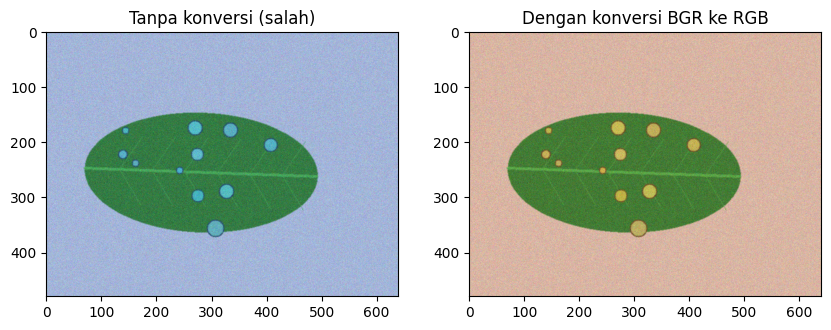

In [4]:
os.chdir('/content/drive/MyDrive/simuteh-2330511031/notebook')

import sys
sys.path.append("../src")
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")

In [7]:
import os
os.chdir('/content/drive/MyDrive/simuteh-2330511031')

# 1. Atur identitas
!git config --global user.email "nazwa.syafia2@email.com"
!git config --global user.name "nazwasm"

# 2. Masukkan semua file B1 yang sudah dibuat
!git add .

# 3. Kunci perubahan dengan pesan B1
!git commit -m "B1: setup lingkungan dan formulasi masalah"

# 4. Kirim ke GitHub
!git push -u origin main

branch 'main' set up to track 'origin/main'.
Everything up-to-date
